# Syllabic-Positional Decipherment: 3 Mapping Tables
## LSTM + Mapping conditioned by intra-syllable position

The SilPart model (d=0.445, closest to the Voynich) reveals that 90% of glyph selections are **position-locked** (glyph_overlap=0.1, pos_bias=3.0). The neural v1/v2 models use a single mapping `{glyph → character}`, ignoring that the same glyph could encode different characters depending on its intra-syllable position (onset/nucleus/coda).

**Hypothesis:** A mapping conditioned by intra-syllable position unlocks Hebrew roots that the single mapping obscured, by allowing "polyvalent" glyphs to map to different consonants depending on their syllabic role.

### Design decisions
| Question | Decision |
|----------|----------|
| 1-glyph syllable | → `nucleus` |
| 2-glyph syllable | → first=`onset`, second=`coda` |
| 3+ glyph syllable | → first=`onset`, last=`coda`, middle=`nucleus` |
| Initialisation | All 3 tables start identical (from frequency mapping) → EM diverges them |
| Active entries | Only if glyph appears ≥5 times in that position (MIN_POS_FREQ=5) |
| Temperature | T=2.0 (best from v2) + T=3.0 for comparison |
| Seeds | 10 per T = 20 runs total |

In [1]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, random, json, warnings, time, copy
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from scipy.spatial.distance import jensenshannon
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print('Imports OK')

Device: cuda
Imports OK


In [2]:
# ── Cell 2: Load Voynich corpus ─────────────────────────────────────
STA_PATH = 'corpus/voynich_sta.txt'

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


# ── Segmentation and positional classification ──

def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)
    return silabas_por_palabra, all_trans_probs, threshold_val


def catalogar_silabas(silabas_por_palabra):
    syl_freq = Counter()
    syl_per_word = []
    syl_lengths = Counter()
    count_in_word = 0
    for item in silabas_por_palabra:
        if item is None:
            if count_in_word > 0:
                syl_per_word.append(count_in_word)
            count_in_word = 0
        else:
            syl_freq[item] += 1
            syl_lengths[len(item)] += 1
            count_in_word += 1
    if count_in_word > 0:
        syl_per_word.append(count_in_word)
    return syl_freq, syl_per_word, syl_lengths


def clasificar_silabas_posicionalmente(silabas_por_palabra, min_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)
    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1
    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats


def syls_to_words(syls_flat):
    words, current = [], []
    for item in syls_flat:
        if item is None:
            if current:
                words.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words.append(current)
    return words


def clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB):
    glyph_in_class = defaultdict(Counter)
    glyph_position = defaultdict(Counter)
    for word_syls in WORDS_SYL_V:
        for syl in word_syls:
            clase = clase_silaba_v.get(syl, 'free')
            for i, g in enumerate(syl):
                glyph_in_class[g][clase] += 1
                if i == 0:
                    glyph_position[g]['inicio'] += 1
                elif i == len(syl) - 1:
                    glyph_position[g]['fin'] += 1
                else:
                    glyph_position[g]['medio'] += 1
    glyph_role = {}
    glyph_stats = {}
    for g in VOCAB:
        counts = glyph_in_class[g]
        total = sum(counts.values())
        if total < 5:
            glyph_role[g] = '?'
            glyph_stats[g] = {'role': '?', 'total': total, 'pct_nuclear': 0}
            continue
        pct_nuclear = counts.get('nuclear', 0) / total
        pct_onset = counts.get('onset', 0) / total
        pct_coda = counts.get('coda', 0) / total
        glyph_role[g] = 'V' if pct_nuclear > 0.40 else 'C'
        glyph_stats[g] = {
            'role': glyph_role[g], 'total': total,
            'pct_nuclear': pct_nuclear, 'pct_onset': pct_onset,
            'pct_coda': pct_coda, 'pct_free': counts.get('free', 0) / total,
            'pos_inicio': glyph_position[g].get('inicio', 0),
            'pos_medio': glyph_position[g].get('medio', 0),
            'pos_fin': glyph_position[g].get('fin', 0),
        }
    return glyph_role, glyph_stats


# ── Load and process Voynich ──
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
N_VOYNICH = len(palabras)
glyph_freq = Counter(corpus_plano)

M_raw, M_prob, tokens_tr, index_tr = construir_matriz_transicion_intrapalabra(palabras)
SILABAS_VOYNICH, _, threshold_val = segmentar_silabas_tp(
    palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20)
syl_freq_v, syl_per_word_v, syl_lengths_v = catalogar_silabas(SILABAS_VOYNICH)
clase_silaba_v, stats_syl_v = clasificar_silabas_posicionalmente(SILABAS_VOYNICH, min_freq=5)
WORDS_SYL_V = syls_to_words(SILABAS_VOYNICH)
glyph_role, glyph_stats = clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB)

n_c = sum(1 for g in VOCAB if glyph_role[g] == 'C')
n_v = sum(1 for g in VOCAB if glyph_role[g] == 'V')
n_q = sum(1 for g in VOCAB if glyph_role[g] == '?')
print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano):,} tokens, {len(VOCAB)} glyphs')
print(f'Classification: C={n_c}, V={n_v}, ?={n_q}')

Voynich: 37,087 palabras, 157,254 tokens, 166 glifos
Clasificación: C=70, V=5, ?=91


In [3]:
# ── Cell 3: Load Hebrew corpus + CharLM baseline + grammar anchors ──

def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Hebrew total: {len(todas_words):,} words')
    return todas_palabras

print('Downloading Hebrew corpus (Torah)...')
hebrew_words_full = descargar_hebreo()

# Subsample
rng_sub = np.random.default_rng(42)
if len(hebrew_words_full) > N_VOYNICH:
    idx = rng_sub.choice(len(hebrew_words_full), size=N_VOYNICH, replace=False)
    hebrew_words = [hebrew_words_full[i] for i in sorted(idx)]
else:
    hebrew_words = hebrew_words_full
print(f'Hebrew subsampled: {len(hebrew_words):,} words')

# Hebrew C/V classification
HEBREW_VOWELS = set('אהוי')  # matres lectionis
target_chars_heb = sorted(set(c for w in hebrew_words for c in w))
char_role_heb = {c: 'V' if c in HEBREW_VOWELS else 'C' for c in target_chars_heb}
n_c_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'C')
n_v_h = sum(1 for c in target_chars_heb if char_role_heb[c] == 'V')
print(f'Hebrew: {len(target_chars_heb)} chars (C={n_c_h}, V={n_v_h})')

# ── Trigram CharLM baseline (Witten-Bell) ──
class CharLM:
    def __init__(self, order=3):
        self.order = order
        self.trigram_counts = defaultdict(Counter)
        self.bigram_counts = defaultdict(Counter)
        self.unigram_counts = Counter()
        self.vocab = set()
        self.total = 0
        self._V = 0

    def fit(self, words):
        BOS, EOS = '<w>', '</w>'
        for word in words:
            seq = [BOS, BOS] + list(word) + [EOS]
            for c in seq:
                self.vocab.add(c)
                self.unigram_counts[c] += 1
                self.total += 1
            for i in range(len(seq) - 1):
                self.bigram_counts[seq[i]][seq[i+1]] += 1
            for i in range(len(seq) - 2):
                ctx = (seq[i], seq[i+1])
                self.trigram_counts[ctx][seq[i+2]] += 1
        self._V = len(self.vocab)

    def _log_prob_trigram(self, c1, c2, c3):
        ctx = (c1, c2)
        tri_counts = self.trigram_counts[ctx]
        tri_total = sum(tri_counts.values())
        if tri_total > 0:
            tri_seen = len(tri_counts)
            count = tri_counts.get(c3, 0)
            if count > 0:
                prob = count / (tri_total + tri_seen)
                return math.log2(max(prob, 1e-20))
            else:
                lambda_bo = tri_seen / (tri_total + tri_seen)
                bi_counts = self.bigram_counts[c2]
                bi_total = sum(bi_counts.values())
                if bi_total > 0:
                    bi_seen = len(bi_counts)
                    bi_count = bi_counts.get(c3, 0)
                    if bi_count > 0:
                        prob = lambda_bo * bi_count / (bi_total + bi_seen)
                    else:
                        lambda_bo2 = bi_seen / (bi_total + bi_seen)
                        prob = lambda_bo * lambda_bo2 * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                else:
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
        else:
            bi_counts = self.bigram_counts[c2]
            bi_total = sum(bi_counts.values())
            if bi_total > 0:
                bi_seen = len(bi_counts)
                count = bi_counts.get(c3, 0)
                if count > 0:
                    prob = count / (bi_total + bi_seen)
                else:
                    lambda_bo = bi_seen / (bi_total + bi_seen)
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
            else:
                prob = (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))

    def log_prob(self, word):
        BOS, EOS = '<w>', '</w>'
        seq = [BOS, BOS] + list(word) + [EOS]
        lp = 0.0
        for i in range(2, len(seq)):
            lp += self._log_prob_trigram(seq[i-2], seq[i-1], seq[i])
        return lp

    def perplexity(self, words):
        total_lp, total_n = 0.0, 0
        for word in words:
            total_lp += self.log_prob(word)
            total_n += len(word) + 1
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)

# Train baseline
char_lm_baseline = CharLM(order=3)
char_lm_baseline.fit(hebrew_words)
ppx_baseline = char_lm_baseline.perplexity(hebrew_words)
print(f'CharLM baseline native PPX: {ppx_baseline:.2f}')

# ── Grammar anchors ──
HEBREW_PREFIXES = set('והבכלמש')
HEBREW_SUFFIXES = set('התםןך')
HEBREW_ROOT_CONSONANTS = set('אבגדהוזחטיכלמנסעפצקרשת') - HEBREW_PREFIXES - HEBREW_SUFFIXES

GRAMMAR_ANCHORS = {
    'D1': HEBREW_PREFIXES,
    'K1': HEBREW_PREFIXES | {'ש'},
    'L1': {'ל', 'ה', 'ב', 'מ'},
    'Q1': HEBREW_ROOT_CONSONANTS,
    'Q2': HEBREW_ROOT_CONSONANTS,
    'A2': HEBREW_SUFFIXES,
    'C1': HEBREW_SUFFIXES,
}

def build_glyph_grammar_roles(palabras, glyph_stats, VOCAB):
    glyph_grammar_role = {}
    direct_rules = {
        'D1': 'prefix', 'K1': 'classifier', 'L1': 'prefix',
        'Q1': 'root', 'Q2': 'root',
        'A2': 'suffix', 'C1': 'suffix',
    }
    for g in VOCAB:
        if g in direct_rules:
            glyph_grammar_role[g] = direct_rules[g]
            continue
        s = glyph_stats.get(g, {})
        total = s.get('total', 0)
        if total < 10:
            continue
        pos_ini = s.get('pos_inicio', 0)
        pos_fin = s.get('pos_fin', 0)
        pos_med = s.get('pos_medio', 0)
        pos_total = pos_ini + pos_fin + pos_med
        if pos_total == 0:
            continue
        pct_onset = s.get('pct_onset', 0)
        pct_coda = s.get('pct_coda', 0)
        pct_nuclear = s.get('pct_nuclear', 0)
        r_ini = pos_ini / pos_total
        r_fin = pos_fin / pos_total
        if pct_onset > 0.50 and r_ini > 0.50:
            glyph_grammar_role[g] = 'prefix'
        elif pct_coda > 0.50 and r_fin > 0.50:
            glyph_grammar_role[g] = 'suffix'
        elif pct_nuclear > 0.40:
            glyph_grammar_role[g] = 'root'
    role_to_anchor = {
        'prefix': HEBREW_PREFIXES,
        'classifier': HEBREW_PREFIXES | {'ש'},
        'root': HEBREW_ROOT_CONSONANTS,
        'suffix': HEBREW_SUFFIXES,
    }
    glyph_anchor_sets = {}
    for g, role in glyph_grammar_role.items():
        glyph_anchor_sets[g] = role_to_anchor.get(role, set())
    return glyph_grammar_role, glyph_anchor_sets

glyph_grammar_role, glyph_anchor_sets = build_glyph_grammar_roles(
    palabras, glyph_stats, VOCAB)

role_counts = Counter(glyph_grammar_role.values())
print(f'\nGrammar anchors: {len(glyph_grammar_role)} glyphs')
for role, cnt in sorted(role_counts.items(), key=lambda x: -x[1]):
    print(f'  {role}: {cnt}')

Descargando corpus hebreo (Torah)...
  Descargando Genesis...
  Descargando Exodus...
  Descargando Leviticus...
  Descargando Numbers...
  Descargando Deuteronomy...
  Hebreo total: 80,051 palabras
Hebreo subsampleado: 37,087 palabras
Hebreo: 27 chars (C=23, V=4)
CharLM baseline PPX nativa: 7.32

Grammar anchors: 12 glifos
  root: 7
  suffix: 2
  prefix: 2
  classifier: 1


In [4]:
# ── Cell 4: NeuralCharLM — LSTM architecture ─────────────────────────

class CharDataset(Dataset):
    def __init__(self, words, char2idx):
        self.samples = []
        bos = char2idx['<w>']
        eos = char2idx['</w>']
        for word in words:
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(indices)):
                ctx = indices[i-2:i]
                target = indices[i]
                self.samples.append((ctx, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ctx, target = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(target, dtype=torch.long)


class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0,
                           batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden

    def log_prob(self, word, temperature=1.0):
        self.eval()
        with torch.no_grad():
            bos = self.char2idx['<w>']
            eos = self.char2idx['</w>']
            unk = self.char2idx.get('<unk>', 0)
            indices = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
            total_lp = 0.0
            for i in range(2, len(indices)):
                ctx = torch.tensor([[indices[i-2], indices[i-1]]], device=DEVICE)
                logits, _ = self.forward(ctx)
                logits_t = logits[0, -1, :] / temperature
                log_probs = torch.log_softmax(logits_t, dim=0)
                total_lp += log_probs[indices[i]].item() / math.log(2)
            return total_lp

    def batch_log_prob(self, words, temperature=1.0):
        self.eval()
        bos = self.char2idx['<w>']
        eos = self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)
        with torch.no_grad():
            all_ctx = []
            all_tgt = []
            word_boundaries = [0]
            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                word_boundaries.append(len(all_ctx))
            n_total = len(all_ctx)
            if n_total == 0:
                return np.zeros(len(words))
            ctx_t = torch.tensor(all_ctx, device=DEVICE)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)
            CHUNK = 16384
            all_lps = []
            for start in range(0, n_total, CHUNK):
                end = min(start + CHUNK, n_total)
                logits, _ = self.forward(ctx_t[start:end])
                logits_last = logits[:, -1, :] / temperature
                log_p = torch.log_softmax(logits_last, dim=-1)
                target_lp = log_p.gather(1, tgt_t[start:end].unsqueeze(1)).squeeze(1)
                all_lps.append(target_lp)
            all_lps = torch.cat(all_lps).cpu().numpy() / math.log(2)
            word_lps = np.zeros(len(words))
            for wi in range(len(words)):
                start = word_boundaries[wi]
                end = word_boundaries[wi + 1]
                if start < end:
                    word_lps[wi] = all_lps[start:end].sum()
            return word_lps

    def perplexity(self, words, temperature=1.0):
        self.eval()
        word_lps = self.batch_log_prob(words, temperature)
        total_lp = word_lps.sum()
        total_n = sum(len(w) + 1 for w in words)
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# ── Build vocabulary and indices ──
all_chars_heb = sorted(set(c for w in hebrew_words for c in w))
special_tokens = ['<pad>', '<w>', '</w>', '<unk>']
char_vocab = special_tokens + all_chars_heb
char2idx = {c: i for i, c in enumerate(char_vocab)}
idx2char = {i: c for c, i in char2idx.items()}

print(f'Neural LM vocab: {len(char_vocab)} tokens ({len(all_chars_heb)} chars + {len(special_tokens)} special)')
n_params = sum(p.numel() for p in NeuralCharLM(len(char_vocab)).parameters())
print(f'Parameters: {n_params:,}')

Neural LM vocab: 31 tokens (27 chars + 4 special)
Parámetros: 476,991


Train: 29,670 words, Val: 7,417 words
Train samples: 142,813, Val samples: 35,563

Entrenando Neural LM (30 epochs, patience=5)...
  Epoch  1: train_loss=2.3443, val_loss=2.1331, lr=0.001995
  Epoch  5: train_loss=2.0591, val_loss=2.0283, lr=0.001866
  Epoch 10: train_loss=2.0326, val_loss=2.0189, lr=0.001500
  Epoch 15: train_loss=2.0205, val_loss=2.0111, lr=0.001000
  Epoch 20: train_loss=2.0096, val_loss=2.0057, lr=0.000500
  Epoch 25: train_loss=2.0040, val_loss=2.0041, lr=0.000134
  Epoch 30: train_loss=2.0006, val_loss=2.0039, lr=0.000000

Entrenamiento completado en 48.5s

Perplexity en validación (2000 words):
  CharLM trigram (baseline): 7.37
  NeuralCharLM (T=1.0):     7.49


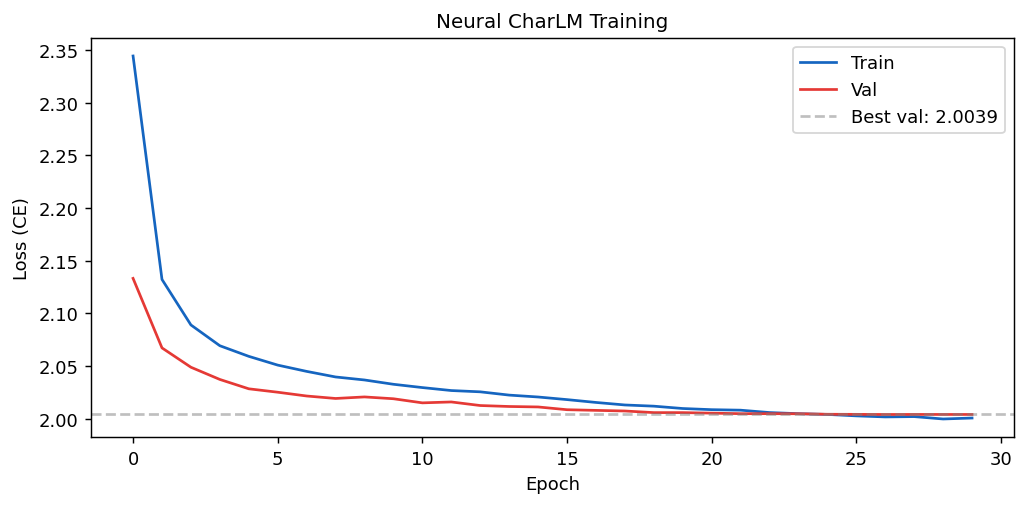

In [5]:
# ── Cell 5: Neural LM training ──────────────────────────────

rng_split = np.random.default_rng(42)
n_val = int(0.2 * len(hebrew_words))
perm = rng_split.permutation(len(hebrew_words))
val_idx = set(perm[:n_val])
train_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i not in val_idx]
val_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i in val_idx]
print(f'Train: {len(train_words):,} words, Val: {len(val_words):,} words')

train_dataset = CharDataset(train_words, char2idx)
val_dataset = CharDataset(val_words, char2idx)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)
print(f'Train samples: {len(train_dataset):,}, Val samples: {len(val_dataset):,}')

neural_lm = NeuralCharLM(len(char_vocab), embed_dim=32, hidden_dim=192,
                          n_layers=2, dropout=0.2).to(DEVICE)
neural_lm.char2idx = char2idx
neural_lm.idx2char = idx2char

optimizer = optim.AdamW(neural_lm.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
criterion = nn.CrossEntropyLoss(ignore_index=char2idx['<pad>'])

N_EPOCHS = 30
PATIENCE = 5
best_val_loss = float('inf')
patience_counter = 0
train_losses = []
val_losses = []

print(f'\nTraining Neural LM ({N_EPOCHS} epochs, patience={PATIENCE})...')
t0 = time.time()

for epoch in range(N_EPOCHS):
    neural_lm.train()
    epoch_loss = 0.0
    n_batches = 0
    for ctx_batch, target_batch in train_loader:
        ctx_batch = ctx_batch.to(DEVICE)
        target_batch = target_batch.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = neural_lm(ctx_batch)
        loss = criterion(logits[:, -1, :], target_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    train_loss = epoch_loss / max(n_batches, 1)
    train_losses.append(train_loss)

    neural_lm.eval()
    val_loss = 0.0
    n_val_batches = 0
    with torch.no_grad():
        for ctx_batch, target_batch in val_loader:
            ctx_batch = ctx_batch.to(DEVICE)
            target_batch = target_batch.to(DEVICE)
            logits, _ = neural_lm(ctx_batch)
            loss = criterion(logits[:, -1, :], target_batch)
            val_loss += loss.item()
            n_val_batches += 1
    val_loss = val_loss / max(n_val_batches, 1)
    val_losses.append(val_loss)
    scheduler.step()

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f'  Epoch {epoch+1:2d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, '
              f'lr={scheduler.get_last_lr()[0]:.6f}')

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0
        best_state_dict = copy.deepcopy(neural_lm.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'  Early stopping at epoch {epoch+1}')
            break

elapsed = time.time() - t0
print(f'\nTraining completed in {elapsed:.1f}s')

neural_lm.load_state_dict(best_state_dict)

neural_val_ppx = neural_lm.perplexity(val_words[:2000], temperature=1.0)
baseline_val_ppx = char_lm_baseline.perplexity(val_words[:2000])
print(f'\nPerplexity on validation (2000 words):')
print(f'  CharLM trigram (baseline): {baseline_val_ppx:.2f}')
print(f'  NeuralCharLM (T=1.0):     {neural_val_ppx:.2f}')

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(train_losses, label='Train', color='#1565C0')
ax.plot(val_losses, label='Val', color='#E53935')
ax.axhline(best_val_loss, linestyle='--', color='gray', alpha=0.5, label=f'Best val: {best_val_loss:.4f}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (CE)')
ax.set_title('Neural CharLM Training')
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
# -- Cell 6: Intra-syllable positions + PositionalGlyphMappingState + Scoring --

# ══════════════════════════════════════════════════════════════════════
# Part A: Count intra-syllable positions per glyph
# ══════════════════════════════════════════════════════════════════════

MIN_POS_FREQ = 5

def compute_intra_syllable_positions(words_syl):
    """For each glyph, count occurrences as onset/nucleus/coda."""
    pos_counts = defaultdict(lambda: Counter())  # glyph -> Counter(onset/nucleus/coda)
    for word_syls in words_syl:
        for syl in word_syls:
            n = len(syl)
            if n == 1:
                pos_counts[syl[0]]['nucleus'] += 1
            elif n == 2:
                pos_counts[syl[0]]['onset'] += 1
                pos_counts[syl[1]]['coda'] += 1
            else:  # 3+
                pos_counts[syl[0]]['onset'] += 1
                pos_counts[syl[-1]]['coda'] += 1
                for g in syl[1:-1]:
                    pos_counts[g]['nucleus'] += 1
    return pos_counts

intra_pos_counts = compute_intra_syllable_positions(WORDS_SYL_V)
print(f'Glyphs with positional data: {len(intra_pos_counts)}')

# ══════════════════════════════════════════════════════════════════════
# Part B: Determine active positions per glyph
# ══════════════════════════════════════════════════════════════════════

def compute_active_positions(intra_pos_counts, min_freq=MIN_POS_FREQ):
    """For each glyph, return set of positions where freq >= min_freq.
    Fallback: if no position >= min_freq, assign the most frequent one."""
    glyph_active = {}
    for g, counts in intra_pos_counts.items():
        active = {pos for pos, cnt in counts.items() if cnt >= min_freq}
        if not active:
            # Fallback: most frequent position
            best_pos = max(counts, key=counts.get)
            active = {best_pos}
        glyph_active[g] = active
    return glyph_active

glyph_active_positions = compute_active_positions(intra_pos_counts)

n_1pos = sum(1 for s in glyph_active_positions.values() if len(s) == 1)
n_2pos = sum(1 for s in glyph_active_positions.values() if len(s) == 2)
n_3pos = sum(1 for s in glyph_active_positions.values() if len(s) == 3)
total_entries = sum(len(s) for s in glyph_active_positions.values())
print(f'Glyphs active in 1 position: {n_1pos}')
print(f'Glyphs active in 2 positions: {n_2pos}')
print(f'Glyphs active in 3 positions: {n_3pos}')
print(f'Total mapping entries: {total_entries}')

# ══════════════════════════════════════════════════════════════════════
# Part C: PositionalGlyphMappingState
# ══════════════════════════════════════════════════════════════════════

POSITIONS = ['onset', 'nucleus', 'coda']

class PositionalGlyphMappingState:
    """Mapping with 3 tables: onset, nucleus, coda."""

    def __init__(self, voynich_glyphs, target_chars, glyph_role=None,
                 char_role=None, glyph_active_positions=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.glyph_active_positions = glyph_active_positions or {}
        # 3 tables
        self.mapping_onset = {}
        self.mapping_nucleus = {}
        self.mapping_coda = {}

    def _get_table(self, pos):
        if pos == 'onset': return self.mapping_onset
        if pos == 'nucleus': return self.mapping_nucleus
        return self.mapping_coda

    def _set_table(self, pos, table):
        if pos == 'onset': self.mapping_onset = table
        elif pos == 'nucleus': self.mapping_nucleus = table
        else: self.mapping_coda = table

    def set_all_from_flat(self, mapping):
        """Initialize all 3 tables from a flat mapping (identical at start)."""
        self.mapping_onset = dict(mapping)
        self.mapping_nucleus = dict(mapping)
        self.mapping_coda = dict(mapping)

    def copy(self):
        new = PositionalGlyphMappingState(
            self.voynich_glyphs, self.target_chars,
            self.glyph_role, self.char_role, self.glyph_active_positions)
        new.mapping_onset = dict(self.mapping_onset)
        new.mapping_nucleus = dict(self.mapping_nucleus)
        new.mapping_coda = dict(self.mapping_coda)
        return new

    def propose_change_tracked(self, rng, constrained=True):
        """Pick a random entry (glyph, active position), change char.
        Returns (new_state, glyph, pos)."""
        new = self.copy()
        glyph = rng.choice(self.voynich_glyphs)
        active = self.glyph_active_positions.get(glyph, {'nucleus'})
        pos = rng.choice(list(active))
        table = new._get_table(pos)

        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        table[glyph] = rng.choice(candidates)
        new._set_table(pos, table)
        return new, glyph, pos

    def apply_word_positional(self, word_glyphs, word_syls):
        """Apply mapping according to the intra-syllable position of each glyph."""
        # Build position assignment for each glyph in the word
        glyph_positions = []
        glyph_idx = 0
        for syl in word_syls:
            n = len(syl)
            for i_s, g in enumerate(syl):
                if n == 1:
                    glyph_positions.append('nucleus')
                elif n == 2:
                    glyph_positions.append('onset' if i_s == 0 else 'coda')
                else:
                    if i_s == 0:
                        glyph_positions.append('onset')
                    elif i_s == n - 1:
                        glyph_positions.append('coda')
                    else:
                        glyph_positions.append('nucleus')

        result = []
        for i, g in enumerate(word_glyphs):
            if i < len(glyph_positions):
                pos = glyph_positions[i]
            else:
                pos = 'nucleus'  # fallback
            table = self._get_table(pos)
            result.append(table.get(g, '?'))
        return result

    @property
    def mapping(self):
        """Return dominant flat mapping (nucleus, for scoring compatibility)."""
        return dict(self.mapping_nucleus)

    def n_divergent(self):
        """Count glyphs with different chars across active positions."""
        n = 0
        for g in self.voynich_glyphs:
            active = self.glyph_active_positions.get(g, set())
            if len(active) < 2:
                continue
            chars_at_pos = set()
            for pos in active:
                table = self._get_table(pos)
                if g in table:
                    chars_at_pos.add(table[g])
            if len(chars_at_pos) > 1:
                n += 1
        return n

    def n_multi_position(self):
        """Count glyphs active in >1 position."""
        return sum(1 for g in self.voynich_glyphs
                   if len(self.glyph_active_positions.get(g, set())) > 1)

# ══════════════════════════════════════════════════════════════════════
# Part D: Positional scoring
# ══════════════════════════════════════════════════════════════════════

def build_positional_word_index(words_syl):
    """Index: (glyph, pos) -> [word_indices] for incremental scoring."""
    idx = defaultdict(list)
    for wi, word_syls in enumerate(words_syl):
        for syl in word_syls:
            n = len(syl)
            for i_s, g in enumerate(syl):
                if n == 1:
                    pos = 'nucleus'
                elif n == 2:
                    pos = 'onset' if i_s == 0 else 'coda'
                else:
                    if i_s == 0: pos = 'onset'
                    elif i_s == n - 1: pos = 'coda'
                    else: pos = 'nucleus'
                idx[(g, pos)].append(wi)
    # Deduplicate
    for key in idx:
        idx[key] = sorted(set(idx[key]))
    return idx


def score_positional_cv(state, glyph_role, char_role):
    """Score C/V consistency across all 3 tables."""
    n_ok, n_total = 0, 0
    for pos in POSITIONS:
        table = state._get_table(pos)
        for g, c in table.items():
            gr = glyph_role.get(g, '?')
            if gr == '?':
                continue
            n_total += 1
            if char_role.get(c) == gr:
                n_ok += 1
    return n_ok / max(n_total, 1)


def score_grammar_positional(state, glyph_anchor_sets):
    """Grammar score: uses nucleus mapping (dominant)."""
    if not glyph_anchor_sets:
        return 0.0
    n_anchored, score = 0, 0.0
    mapping = state.mapping  # nucleus
    for g, anchor_set in glyph_anchor_sets.items():
        if not anchor_set:
            continue
        n_anchored += 1
        if mapping.get(g) in anchor_set:
            score += 1.0
        else:
            score -= 1.0
    return score / max(n_anchored, 1)


def score_entropy_positional(state):
    """Entropy across all 3 tables combined."""
    all_chars = []
    for pos in POSITIONS:
        table = state._get_table(pos)
        all_chars.extend(table.values())
    char_counts = Counter(all_chars)
    if len(char_counts) <= 1:
        return 0.0
    total = sum(char_counts.values())
    probs = np.array([c / total for c in char_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(char_counts))
    return H / H_max if H_max > 1e-10 else 0.0


def score_cardinality_positional(state, K_max=23):
    """Cardinality: distinct chars across all 3 tables combined."""
    all_chars = set()
    for pos in POSITIONS:
        table = state._get_table(pos)
        all_chars.update(table.values())
    K = len(all_chars)
    if K >= K_max:
        return 0.0
    return -((K_max - K) ** 2)


def score_neural_lm_positional_batch(state, words_sample, words_syl_sample,
                                      neural_lm, temperature=1.0):
    """LM score using apply_word_positional."""
    mapped = [state.apply_word_positional(w, ws)
              for w, ws in zip(words_sample, words_syl_sample)]
    word_lps = neural_lm.batch_log_prob(mapped, temperature)
    return float(np.mean(word_lps)), word_lps


def score_total_positional(state, words_sample, words_syl_sample, neural_lm, temperature,
                           glyph_role, char_role, glyph_anchor_sets,
                           w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                           w_gram=1.0, K_max=23):
    s_lm, word_lps = score_neural_lm_positional_batch(
        state, words_sample, words_syl_sample, neural_lm, temperature)
    s_pos = score_positional_cv(state, glyph_role, char_role)
    s_card = score_cardinality_positional(state, K_max)
    s_ent = score_entropy_positional(state)
    s_gram = score_grammar_positional(state, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, word_lps


def score_total_positional_incremental(proposal, changed_glyph, changed_pos,
                                        words_sample, words_syl_sample,
                                        neural_lm, temperature,
                                        glyph_role, char_role, glyph_anchor_sets,
                                        pos_word_idx, prev_word_lps,
                                        w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3,
                                        w_gram=1.0, K_max=23):
    new_word_lps = prev_word_lps.copy()
    affected = pos_word_idx.get((changed_glyph, changed_pos), [])
    if affected:
        affected_mapped = [proposal.apply_word_positional(words_sample[wi], words_syl_sample[wi])
                           for wi in affected]
        new_lps = neural_lm.batch_log_prob(affected_mapped, temperature)
        for j, wi in enumerate(affected):
            new_word_lps[wi] = new_lps[j]
    s_lm = float(np.mean(new_word_lps))
    s_pos = score_positional_cv(proposal, glyph_role, char_role)
    s_card = score_cardinality_positional(proposal, K_max)
    s_ent = score_entropy_positional(proposal)
    s_gram = score_grammar_positional(proposal, glyph_anchor_sets)
    total = (w_lm * s_lm + w_pos * s_pos + w_card * s_card
             + w_ent * s_ent + w_gram * s_gram)
    return total, new_word_lps

# ══════════════════════════════════════════════════════════════════════
# Part E: Root helpers + init_frequency_mapping
# ══════════════════════════════════════════════════════════════════════

HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')
HEBREW_ROOTS = {
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}

def extract_skeleton_deterministic(mapped_word):
    """Strip matres lectionis, return consonants only."""
    skeleton = []
    for char in mapped_word:
        if char in HEBREW_MATRES:
            continue
        if char in HEBREW_CONSONANTS_SET:
            skeleton.append(char)
    return ''.join(skeleton)

def count_roots_positional(state, palabras_sample, words_syl_sample, top_n=200):
    """Root count using positional mapping."""
    word_freq = Counter(tuple(w) for w in palabras_sample)
    top_words = word_freq.most_common(top_n)
    # Build word->syls lookup
    word_to_syls = {}
    for w, ws in zip(palabras_sample, words_syl_sample):
        key = tuple(w)
        if key not in word_to_syls:
            word_to_syls[key] = ws

    roots_matched = set()
    n_matches = 0
    for word_tuple, freq in top_words:
        word_glyphs = list(word_tuple)
        syls = word_to_syls.get(word_tuple, [tuple(word_glyphs)])
        mapped = state.apply_word_positional(word_glyphs, syls)
        skel = extract_skeleton_deterministic(mapped)
        if len(skel) < 3:
            continue
        for i in range(len(skel) - 2):
            trigram = skel[i:i+3]
            if trigram in HEBREW_ROOTS:
                roots_matched.add(trigram)
                n_matches += 1
    return roots_matched, n_matches


def init_frequency_mapping(palabras, vocab_glyphs, target_chars, target_words,
                           glyph_role, char_role):
    gf = Counter(g for p in palabras for g in p)
    cf = Counter(c for w in target_words for c in w)
    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: gf[g], reverse=True)
        if role == '?':
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars if char_role.get(c) == role],
                             key=lambda c: cf.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


print('Scoring positional + root helpers loaded')
print(f'Hebrew roots: {len(HEBREW_ROOTS)}')
print(f'Positions: {POSITIONS}')

Glifos con datos posicionales: 166
Glifos activos en 1 posicion: 122
Glifos activos en 2 posiciones: 29
Glifos activos en 3 posiciones: 15
Total entradas de mapping: 225
Scoring posicional + root helpers loaded
Hebrew roots: 100
Posiciones: ['onset', 'nucleus', 'coda']


Top-30 glifos: distribucion posicional intra-silaba
Glifo  Freq  Onset  Nucleus  Coda            Activas  N_pos
   A1 25106   8011    12053  5042 coda/nucleus/onset      3
   A2 17464   1528     2465 13471 coda/nucleus/onset      3
   A3 14545   2862     9930  1753 coda/nucleus/onset      3
   K1 11066   4770     5182  1114 coda/nucleus/onset      3
   B2 10668   1077     3035  6556 coda/nucleus/onset      3
   B1 10492   4992     5019   481 coda/nucleus/onset      3
   J1 10257    133     8552  1572 coda/nucleus/onset      3
   Q1  9935   1257     7176  1502 coda/nucleus/onset      3
   C1  6770    326     1390  5054 coda/nucleus/onset      3
   Q2  6113   1171     4340   602 coda/nucleus/onset      3
   D1  5425   5292      133     0      nucleus/onset      2
   K2  4442    799     2999   644 coda/nucleus/onset      3
   L1  4174   3280      892     2      nucleus/onset      2
   G1  4162      4      325  3833       coda/nucleus      2
   C2  2837   1176     1572    89 coda/nucleus/o

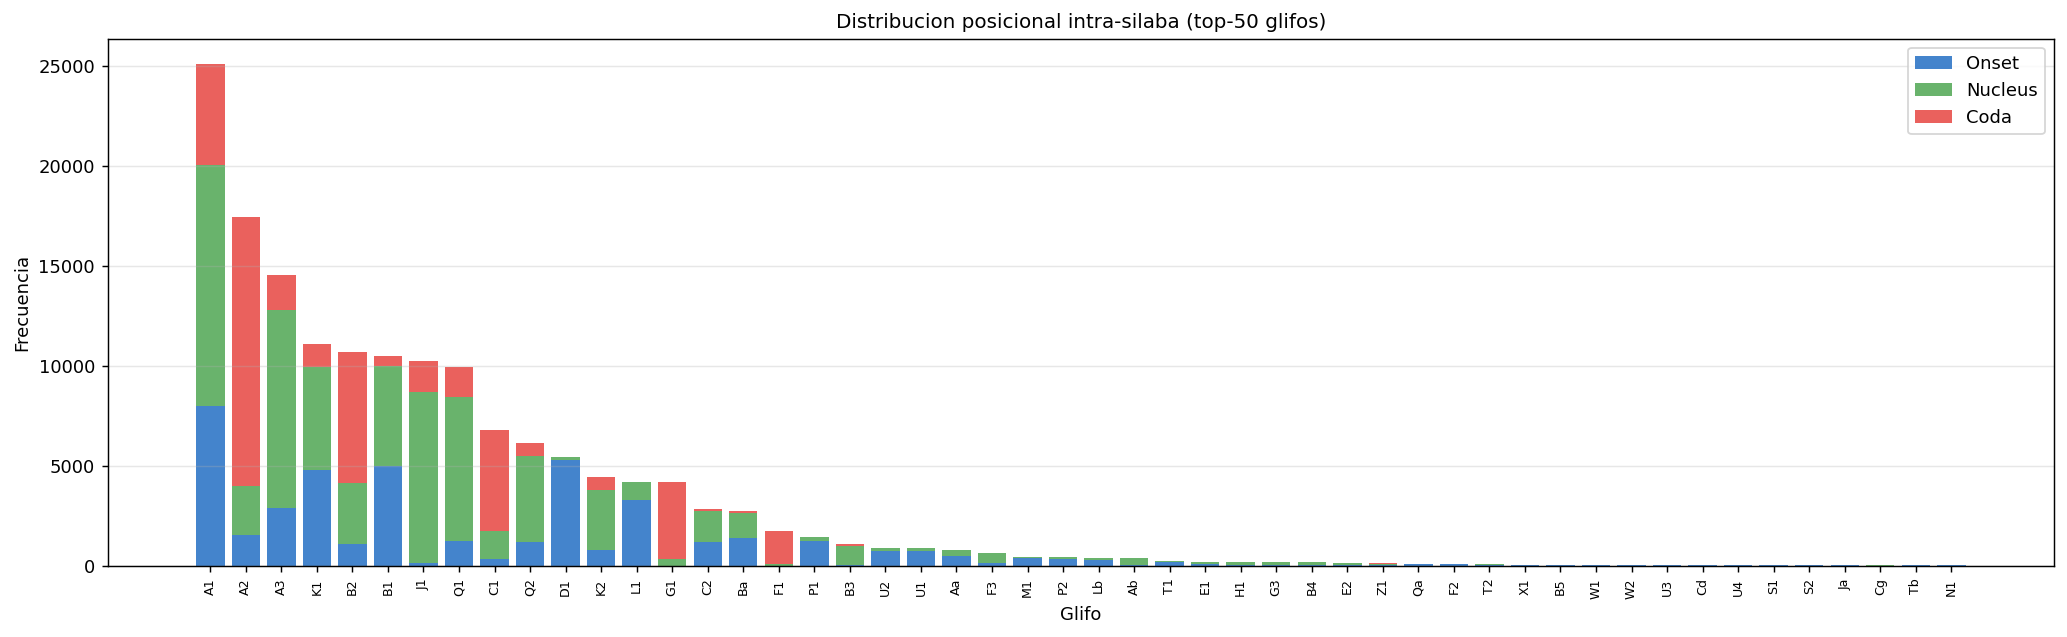

In [7]:
# -- Cell 7: Positional distribution analysis --

# Table: top-30 glyphs with onset/nucleus/coda counts and active positions
top30 = sorted(VOCAB, key=lambda g: glyph_freq[g], reverse=True)[:30]
rows = []
for g in top30:
    counts = intra_pos_counts.get(g, Counter())
    active = glyph_active_positions.get(g, set())
    rows.append({
        'Glyph': g,
        'Freq': glyph_freq[g],
        'Onset': counts.get('onset', 0),
        'Nucleus': counts.get('nucleus', 0),
        'Coda': counts.get('coda', 0),
        'Active': '/'.join(sorted(active)),
        'N_pos': len(active),
    })
df_pos = pd.DataFrame(rows)
print('Top-30 glyphs: intra-syllable positional distribution')
print(df_pos.to_string(index=False))

# Statistics
print(f'\n--- Statistics ---')
print(f'Glyphs active in 1 position: {n_1pos} ({100*n_1pos/len(VOCAB):.0f}%)')
print(f'Glyphs active in 2 positions: {n_2pos} ({100*n_2pos/len(VOCAB):.0f}%)')
print(f'Glyphs active in 3 positions: {n_3pos} ({100*n_3pos/len(VOCAB):.0f}%)')
print(f'Total mapping entries: {total_entries} (vs {len(VOCAB)} in flat model)')
pct_locked = 100 * n_1pos / len(VOCAB)
print(f'\nSilPart premise (>60% position-locked): {pct_locked:.0f}% -> '
      f'{"CONFIRMED" if pct_locked > 60 else "NOT CONFIRMED"}')

# Plot: stacked bars onset/nucleus/coda for top-50 glyphs
top50 = sorted(VOCAB, key=lambda g: glyph_freq[g], reverse=True)[:50]
onset_vals = [intra_pos_counts.get(g, Counter()).get('onset', 0) for g in top50]
nucleus_vals = [intra_pos_counts.get(g, Counter()).get('nucleus', 0) for g in top50]
coda_vals = [intra_pos_counts.get(g, Counter()).get('coda', 0) for g in top50]

fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(top50))
ax.bar(x, onset_vals, label='Onset', color='#1565C0', alpha=0.8)
ax.bar(x, nucleus_vals, bottom=onset_vals, label='Nucleus', color='#43A047', alpha=0.8)
ax.bar(x, coda_vals, bottom=[o+n for o,n in zip(onset_vals, nucleus_vals)],
       label='Coda', color='#E53935', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(top50, rotation=90, fontsize=7)
ax.set_xlabel('Glyph')
ax.set_ylabel('Frequency')
ax.set_title('Intra-syllable positional distribution (top-50 glyphs)')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [8]:
# -- Cell 8: Multi-Seed EM with positional mapping --

N_SEEDS = 10
T_VALUES = [2.0, 3.0]
SCORE_KW = dict(w_gram=2.0, w_card=0.5, K_max=20)
SAMPLE_EM = 3000
EM_ITERS = 2000
EM_PATIENCE = 100
PROPOSALS_PER_ITER = 200

# Prepare EM sample
rng_sample = np.random.default_rng(42)
if len(palabras) > SAMPLE_EM:
    idx_em = rng_sample.choice(len(palabras), size=SAMPLE_EM, replace=False)
    words_em = [palabras[i] for i in idx_em]
    words_syl_em = [WORDS_SYL_V[i] for i in idx_em]
else:
    words_em = palabras
    words_syl_em = WORDS_SYL_V

pos_word_idx_em = build_positional_word_index(words_syl_em)

# Base frequency mapping
base_mapping = init_frequency_mapping(
    palabras, VOCAB, target_chars_heb, hebrew_words,
    glyph_role, char_role_heb)

em_results = []

print(f'Multi-Seed EM positional: {N_SEEDS} seeds x {len(T_VALUES)} T = {N_SEEDS*len(T_VALUES)} runs')
print(f'{SAMPLE_EM} words, {EM_ITERS} iter, patience={EM_PATIENCE}, {PROPOSALS_PER_ITER} prop/iter')
print(f'Seeds 0-4: freq+scramble, seeds 5-9: random C/V')
print()

for T_val in T_VALUES:
    print(f'--- T = {T_val} ---')
    for seed_idx in range(N_SEEDS):
        rng = np.random.default_rng(42 + seed_idx * 137 + int(T_val * 100))

        # Initialize positional state
        state = PositionalGlyphMappingState(
            VOCAB, target_chars_heb, glyph_role, char_role_heb, glyph_active_positions)

        if seed_idx < 5:
            # Frequency mapping + partial random scramble
            mapping_init = dict(base_mapping)
            glyphs_to_scramble = rng.choice(VOCAB, size=max(1, len(VOCAB) // 3), replace=False)
            for g in glyphs_to_scramble:
                role = glyph_role.get(g, '?')
                if role in ('C', 'V'):
                    candidates = [c for c in target_chars_heb if char_role_heb.get(c) == role]
                else:
                    candidates = target_chars_heb
                mapping_init[g] = rng.choice(candidates)
            state.set_all_from_flat(mapping_init)
        else:
            # Fully random mapping (respecting C/V roles)
            mapping_init = {}
            for g in VOCAB:
                role = glyph_role.get(g, '?')
                if role in ('C', 'V'):
                    candidates = [c for c in target_chars_heb if char_role_heb.get(c) == role]
                else:
                    candidates = target_chars_heb
                mapping_init[g] = rng.choice(candidates)
            state.set_all_from_flat(mapping_init)

        # Initial scoring
        best_score, best_word_lps = score_total_positional(
            state, words_em, words_syl_em, neural_lm, T_val,
            glyph_role, char_role_heb, glyph_anchor_sets, **SCORE_KW)
        best_state = state
        no_improve = 0

        t0 = time.time()
        for it in range(EM_ITERS):
            improved = False
            for _ in range(PROPOSALS_PER_ITER):
                proposal, changed_glyph, changed_pos = best_state.propose_change_tracked(
                    rng, constrained=True)
                prop_score, prop_word_lps = score_total_positional_incremental(
                    proposal, changed_glyph, changed_pos,
                    words_em, words_syl_em, neural_lm, T_val,
                    glyph_role, char_role_heb, glyph_anchor_sets,
                    pos_word_idx_em, best_word_lps, **SCORE_KW)
                if prop_score > best_score:
                    best_state = proposal
                    best_score = prop_score
                    best_word_lps = prop_word_lps
                    improved = True

            if not improved:
                no_improve += 1
                if no_improve >= EM_PATIENCE:
                    break
            else:
                no_improve = 0

        elapsed = time.time() - t0
        K_eff = len(set(best_state.mapping.values()))
        gram = score_grammar_positional(best_state, glyph_anchor_sets)
        roots_found, n_matches = count_roots_positional(
            best_state, palabras, WORDS_SYL_V)
        n_div = best_state.n_divergent()
        n_multi = best_state.n_multi_position()

        result = {
            'T': T_val, 'seed': seed_idx, 'score': best_score, 'K_eff': K_eff,
            'grammar': gram, 'n_roots': len(roots_found), 'roots': roots_found,
            'n_matches': n_matches, 'elapsed': elapsed,
            'state': best_state, 'word_lps': best_word_lps,
            'iter_converged': it + 1,
            'n_divergent': n_div, 'n_multi': n_multi,
        }
        em_results.append(result)

        init_type = 'freq+scramble' if seed_idx < 5 else 'random_CV'
        print(f'  Seed {seed_idx:2d} [{init_type:13s}]: score={best_score:.4f}, K={K_eff:2d}, '
              f'gram={gram:.2f}, roots={len(roots_found):2d}, div={n_div:2d}/{n_multi}, '
              f'iter={it+1}, {elapsed:.0f}s')

# Summary table
print(f'\n{"="*70}')
print('EM Positional -- Summary')
print(f'{"="*70}')
df_em = pd.DataFrame([{
    'T': r['T'], 'Seed': r['seed'],
    'Init': 'freq' if r['seed'] < 5 else 'rand',
    'Score': f"{r['score']:.4f}", 'K_eff': r['K_eff'],
    'Grammar': f"{r['grammar']:.2f}", 'Roots': r['n_roots'],
    'Divergent': f"{r['n_divergent']}/{r['n_multi']}",
    'Iter': r['iter_converged'], 'Time': f"{r['elapsed']:.0f}s"
} for r in em_results])
print(df_em.to_string(index=False))

for T_val in T_VALUES:
    runs_t = [r for r in em_results if r['T'] == T_val]
    scores_t = [r['score'] for r in runs_t]
    roots_t = [r['n_roots'] for r in runs_t]
    div_t = [r['n_divergent'] for r in runs_t]
    print(f'\nT={T_val}: score={np.mean(scores_t):.4f}+-{np.std(scores_t):.4f}, '
          f'roots={np.mean(roots_t):.1f}+-{np.std(roots_t):.1f}, '
          f'div={np.mean(div_t):.1f}+-{np.std(div_t):.1f}')

Multi-Seed EM posicional: 10 seeds x 2 T = 20 runs
3000 words, 2000 iter, patience=100, 200 prop/iter
Seeds 0-4: freq+scramble, seeds 5-9: random C/V

--- T = 2.0 ---
  Seed  0 [freq+scramble]: score=-34.8192, K=27, gram=0.83, roots= 3, div=40/44, iter=436, 74s
  Seed  1 [freq+scramble]: score=-34.2800, K=27, gram=1.00, roots= 5, div=38/44, iter=1021, 170s
  Seed  2 [freq+scramble]: score=-33.4982, K=27, gram=1.00, roots= 1, div=35/44, iter=499, 83s
  Seed  3 [freq+scramble]: score=-35.2497, K=27, gram=1.00, roots= 3, div=42/44, iter=589, 96s
  Seed  4 [freq+scramble]: score=-35.2627, K=27, gram=0.83, roots= 2, div=39/44, iter=537, 92s
  Seed  5 [random_CV    ]: score=-33.4796, K=27, gram=0.67, roots= 0, div=34/44, iter=594, 102s
  Seed  6 [random_CV    ]: score=-33.6147, K=27, gram=1.00, roots= 1, div=36/44, iter=689, 120s
  Seed  7 [random_CV    ]: score=-35.4307, K=27, gram=1.00, roots= 3, div=39/44, iter=512, 89s
  Seed  8 [random_CV    ]: score=-34.0564, K=27, gram=0.83, roots= 0,

In [9]:
# -- Cell 9: Best candidate selection --

print(f'Total runs: {len(em_results)}')

# Filter: K_eff >= 20, grammar >= 0.8, score in top-50%
scores_all = [r['score'] for r in em_results]
score_median = np.median(scores_all)

candidates = [r for r in em_results
              if r['K_eff'] >= 20
              and r['grammar'] >= 0.8
              and r['score'] >= score_median]

print(f'Filtered candidates (K>=20, gram>=0.8, score>=median): {len(candidates)}')

if not candidates:
    print('No candidates meet all criteria. Relaxing: K>=15, gram>=0.5')
    candidates = [r for r in em_results
                  if r['K_eff'] >= 15
                  and r['grammar'] >= 0.5
                  and r['score'] >= score_median]
    print(f'Relaxed candidates: {len(candidates)}')

if not candidates:
    print('Still no candidates. Using all runs.')
    candidates = list(em_results)

# Sort by roots (primary), then score (secondary)
candidates.sort(key=lambda r: (r['n_roots'], r['score']), reverse=True)

# Show top-5
print(f'\nTop-5 candidates:')
df_top = pd.DataFrame([{
    'T': r['T'], 'Seed': r['seed'],
    'Score': f"{r['score']:.4f}",
    'K_eff': r['K_eff'], 'Grammar': f"{r['grammar']:.2f}",
    'Roots': r['n_roots'],
    'Divergent': f"{r['n_divergent']}/{r['n_multi']}",
} for r in candidates[:5]])
print(df_top.to_string(index=False))

# Select best
BEST = candidates[0]
print(f'\nSelected: T={BEST["T"]}, seed={BEST["seed"]} '
      f'(roots={BEST["n_roots"]}, score={BEST["score"]:.4f}, '
      f'divergent={BEST["n_divergent"]}/{BEST["n_multi"]})')

Total runs: 20
Candidatos filtrados (K>=20, gram>=0.8, score>=median): 9

Top-5 candidatos:
  T  Seed    Score  K_eff Grammar  Roots Divergent
2.0     1 -34.2800     27    1.00      5     38/44
3.0     9 -34.0653     27    1.00      2     41/44
3.0     6 -34.1521     27    1.00      2     38/44
2.0     2 -33.4982     27    1.00      1     35/44
2.0     6 -33.6147     27    1.00      1     36/44

Seleccionado: T=2.0, seed=1 (roots=5, score=-34.2800, divergent=38/44)


In [10]:
# -- Cell 10: MCMC multi-chain --

T_mcmc = BEST['T']
print(f'MCMC with: T={T_mcmc}')

MCMC_SAMPLE = 3000
rng_mcmc = np.random.default_rng(42)
if len(palabras) > MCMC_SAMPLE:
    idx_mc = rng_mcmc.choice(len(palabras), size=MCMC_SAMPLE, replace=False)
    words_mcmc = [palabras[i] for i in idx_mc]
    words_syl_mcmc = [WORDS_SYL_V[i] for i in idx_mc]
else:
    words_mcmc = palabras
    words_syl_mcmc = WORDS_SYL_V

pos_word_idx_mcmc = build_positional_word_index(words_syl_mcmc)

N_CHAINS = 4
N_ITER = 20000
BURN_IN = 5000
THIN = 10
SEEDS_MCMC = [42, 137, 256, 999]

# Adaptive temperature calibration
def calibrate_mcmc_temp_positional(state, words_sample, words_syl_sample, neural_lm, T_lm,
                                    glyph_role, char_role, glyph_anchor_sets,
                                    pos_word_idx, n_cal=300, target_accept=0.35, **score_kwargs):
    rng_cal = np.random.default_rng(0)
    neg_deltas = []
    cal_state = state.copy()
    cal_score, cal_word_lps = score_total_positional(
        cal_state, words_sample, words_syl_sample, neural_lm, T_lm,
        glyph_role, char_role, glyph_anchor_sets, **score_kwargs)
    for _ in range(n_cal):
        prop, changed_g, changed_p = cal_state.propose_change_tracked(rng_cal, constrained=True)
        ps, pw = score_total_positional_incremental(
            prop, changed_g, changed_p, words_sample, words_syl_sample,
            neural_lm, T_lm, glyph_role, char_role, glyph_anchor_sets,
            pos_word_idx, cal_word_lps, **score_kwargs)
        d = ps - cal_score
        if d < 0:
            neg_deltas.append(abs(d))
        cal_state = prop
        cal_score = ps
        cal_word_lps = pw
    if neg_deltas:
        median_neg = float(np.median(neg_deltas))
        T_start = median_neg / (-math.log(target_accept))
        T_end = T_start / 100
        return T_start, T_end
    return 1.0, 0.01

T_anneal_start, T_anneal_end = calibrate_mcmc_temp_positional(
    BEST['state'], words_mcmc, words_syl_mcmc, neural_lm, T_mcmc,
    glyph_role, char_role_heb, glyph_anchor_sets,
    pos_word_idx_mcmc, **SCORE_KW)
print(f'Calibrated T_anneal: {T_anneal_start:.6f} -> {T_anneal_end:.8f}')

# Run chains
mcmc_chains = []
global_best = None
global_best_score = -np.inf

for chain_idx in range(N_CHAINS):
    seed = SEEDS_MCMC[chain_idx]
    print(f'\n  Chain {chain_idx+1}/{N_CHAINS} (seed={seed})')
    rng_ch = np.random.default_rng(seed)

    current = BEST['state'].copy()
    current_score, current_word_lps = score_total_positional(
        current, words_mcmc, words_syl_mcmc, neural_lm, T_mcmc,
        glyph_role, char_role_heb, glyph_anchor_sets, **SCORE_KW)

    best_ch = current
    best_ch_score = current_score
    chain_scores = [current_score]
    chain_mappings = []  # Store 3 dicts per sample
    chain_mappings.append({
        'onset': dict(current.mapping_onset),
        'nucleus': dict(current.mapping_nucleus),
        'coda': dict(current.mapping_coda),
    })
    accepted = 0
    _thin = 0

    t0 = time.time()
    for it in range(N_ITER):
        if it < BURN_IN:
            frac = it / BURN_IN
            T_anneal = T_anneal_start * (1 - frac) + (T_anneal_start * 0.5) * frac
        else:
            frac = (it - BURN_IN) / max(N_ITER - BURN_IN - 1, 1)
            T_anneal = (T_anneal_start * 0.5) * ((T_anneal_end / max(T_anneal_start * 0.5, 1e-12)) ** frac)

        proposal, changed_g, changed_p = current.propose_change_tracked(rng_ch, constrained=True)

        prop_score, prop_word_lps = score_total_positional_incremental(
            proposal, changed_g, changed_p, words_mcmc, words_syl_mcmc,
            neural_lm, T_mcmc, glyph_role, char_role_heb, glyph_anchor_sets,
            pos_word_idx_mcmc, current_word_lps, **SCORE_KW)

        delta = prop_score - current_score
        if delta > 0 or rng_ch.random() < math.exp(delta / max(T_anneal, 1e-10)):
            current = proposal
            current_score = prop_score
            current_word_lps = prop_word_lps
            accepted += 1
            if current_score > best_ch_score:
                best_ch = current
                best_ch_score = current_score

        chain_scores.append(current_score)
        _thin += 1
        if _thin % THIN == 0:
            chain_mappings.append({
                'onset': dict(current.mapping_onset),
                'nucleus': dict(current.mapping_nucleus),
                'coda': dict(current.mapping_coda),
            })

        if (it + 1) % 5000 == 0:
            elapsed = time.time() - t0
            print(f'    iter {it+1}: score={current_score:.4f}, best={best_ch_score:.4f}, '
                  f'accept={accepted/(it+1):.1%}, T_ann={T_anneal:.6f} [{elapsed:.0f}s]')

    chain_data = {
        'seed': seed,
        'chain_scores': chain_scores,
        'chain_mappings': chain_mappings,
        'accept_rate': accepted / N_ITER,
        'best_state': best_ch,
        'best_score': best_ch_score,
    }
    mcmc_chains.append(chain_data)

    if best_ch_score > global_best_score:
        global_best_score = best_ch_score
        global_best = best_ch

mcmc_result = {
    'best_state': global_best,
    'best_score': global_best_score,
    'chains': mcmc_chains,
    'n_chains': N_CHAINS,
    'seeds': SEEDS_MCMC,
    'n_iter': N_ITER,
    'burn_in': BURN_IN,
    'thin': THIN,
}

print(f'\n-- MCMC completed --')
print(f'Best score: {global_best_score:.4f}')
print(f'K_eff: {len(set(global_best.mapping.values()))}')
print(f'Divergent: {global_best.n_divergent()}/{global_best.n_multi_position()}')
for i, ch in enumerate(mcmc_chains):
    print(f'  Chain {i+1}: accept={ch["accept_rate"]:.1%}, best={ch["best_score"]:.4f}')

MCMC con: T=2.0
Calibrated T_anneal: 0.000111 -> 0.00000111

  Chain 1/4 (seed=42)
    iter 5000: score=-34.2813, best=-34.2800, accept=47.9%, T_ann=0.000055 [4s]
    iter 10000: score=-34.2804, best=-34.2800, accept=41.4%, T_ann=0.000015 [9s]
    iter 15000: score=-34.2801, best=-34.2800, accept=34.9%, T_ann=0.000004 [12s]
    iter 20000: score=-34.2800, best=-34.2800, accept=28.9%, T_ann=0.000001 [17s]

  Chain 2/4 (seed=137)
    iter 5000: score=-34.2810, best=-34.2800, accept=47.0%, T_ann=0.000055 [4s]
    iter 10000: score=-34.2804, best=-34.2800, accept=41.0%, T_ann=0.000015 [8s]
    iter 15000: score=-34.2801, best=-34.2800, accept=34.8%, T_ann=0.000004 [12s]
    iter 20000: score=-34.2800, best=-34.2800, accept=28.9%, T_ann=0.000001 [17s]

  Chain 3/4 (seed=256)
    iter 5000: score=-34.2810, best=-34.2800, accept=47.2%, T_ann=0.000055 [4s]
    iter 10000: score=-34.2804, best=-34.2800, accept=41.3%, T_ann=0.000015 [8s]
    iter 15000: score=-34.2800, best=-34.2800, accept=34.7

In [11]:
# -- Cell 11: Validation (6 tests) --

# -- Posterior + R-hat (adapted for 3 tables) --
def posterior_positional_multi_chain(mcmc_result, burn_in=5000):
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])
    if not all_post_burn:
        return {}, {}, 0
    # Posterior per (glyph, position) -> char
    counts = defaultdict(lambda: defaultdict(Counter))
    for mapping_set in all_post_burn:
        for pos in POSITIONS:
            table = mapping_set[pos]
            for g, c in table.items():
                counts[pos][g][c] += 1
    n_total = len(all_post_burn)
    posterior = defaultdict(dict)
    for pos in POSITIONS:
        for g in counts[pos]:
            total = sum(counts[pos][g].values())
            posterior[pos][g] = {c: cnt / total for c, cnt in counts[pos][g].items()}
    # R-hat on nucleus (dominant table)
    rhat = {}
    for g in counts['nucleus']:
        map_target = max(counts['nucleus'][g], key=counts['nucleus'][g].get)
        chain_means, chain_ns = [], []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m['nucleus'].get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))
        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue
        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md['nucleus'].get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)
        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)
    return posterior, rhat, n_total

posterior_syl, rhat_syl, n_posterior = posterior_positional_multi_chain(
    mcmc_result, burn_in=BURN_IN)

rhat_vals = [v for v in rhat_syl.values()
             if isinstance(v, (int, float)) and not np.isnan(v) and not np.isinf(v)]
pct_converged = 100 * sum(1 for v in rhat_vals if v < 1.1) / max(len(rhat_vals), 1)
print(f'Posterior samples: {n_posterior}')
print(f'R-hat < 1.1: {pct_converged:.1f}% of {len(rhat_vals)} glyphs')

# Use best MCMC state
mapping_syl = global_best

# -- Helpers --
def positional_distribution(glyph, palabras):
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5; counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    return counts / total if total > 0 else np.array([1/3, 1/3, 1/3])

def corpus_trigram_distribution(words):
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    return {tri: cnt / total for tri, cnt in trigram_counts.items()} if total > 0 else {}

def trigram_jsd(dist1, dist2):
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12; q = q + 1e-12
    p = p / p.sum(); q = q / q.sum()
    return float(jensenshannon(p, q))

# =================================================================
# TEST 1: Collapse coherence
# =================================================================
print('\n' + '='*60)
print('Test 1: Collapse coherence (JSD z-scores)')
print('='*60)

mapping_nucleus = dict(mapping_syl.mapping_nucleus)
groups = defaultdict(list)
for g, c in mapping_nucleus.items():
    groups[c].append(g)
all_glyphs = list(mapping_nucleus.keys())
pos_dists = {g: positional_distribution(g, palabras) for g in all_glyphs}

collapse_results = {}
for char, glyphs in groups.items():
    if len(glyphs) < 3:
        continue
    pairs = list(combinations(glyphs, 2))
    if not pairs:
        continue
    real_jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10)
                 for g1, g2 in pairs]
    real_mean = np.mean(real_jsds)
    rng_null = np.random.default_rng(42)
    null_jsds = []
    for _ in range(200):
        rg = rng_null.choice(all_glyphs, size=len(glyphs), replace=False)
        np_ = list(combinations(rg, 2))
        null_jsds.append(np.mean([jensenshannon(pos_dists[g1]+1e-10, pos_dists[g2]+1e-10) for g1,g2 in np_]))
    null_mean = np.mean(null_jsds)
    null_std = max(np.std(null_jsds), 1e-10)
    z = (real_mean - null_mean) / null_std
    verdict_str = 'STRUCTURED' if z > 1.5 else ('DEGENERATE' if z < -1.5 else 'AMBIGUOUS')
    collapse_results[char] = {'n_glyphs': len(glyphs), 'z_score': z, 'verdict': verdict_str}

mean_z = np.mean([r['z_score'] for r in collapse_results.values()])
n_struct = sum(1 for r in collapse_results.values() if r['verdict'] == 'STRUCTURED')
n_degen = sum(1 for r in collapse_results.values() if r['verdict'] == 'DEGENERATE')
test1_pass = mean_z > -1.0
print(f'mean_z={mean_z:.2f}, STRUCTURED={n_struct}, DEGENERATE={n_degen}')
print(f'Test 1: {"PASS" if test1_pass else "FAIL"} (z > -1.0)')

# =================================================================
# TEST 2: N-gram realism (uses apply_word_positional)
# =================================================================
print('\n' + '='*60)
print('Test 2: N-gram realism (positional mapping)')
print('='*60)

heb_sample = hebrew_words[:5000]
voynich_sample = palabras[:5000]
voynich_syl_sample = WORDS_SYL_V[:5000]
ref_dist = corpus_trigram_distribution(heb_sample)
mapped_real = [mapping_syl.apply_word_positional(w, ws)
               for w, ws in zip(voynich_sample, voynich_syl_sample)]
real_dist = corpus_trigram_distribution(mapped_real)
real_jsd = trigram_jsd(real_dist, ref_dist)

rng_null2 = np.random.default_rng(42)
all_mapped_chars = list(set(mapping_nucleus.values()))
null_jsds2 = []
for _ in tqdm(range(100), desc='Null shuffles'):
    shuf = {g: rng_null2.choice(all_mapped_chars) for g in mapping_nucleus}
    # Create a flat-mapped positional state for null
    ss = PositionalGlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb, glyph_active_positions)
    ss.set_all_from_flat(shuf)
    mapped_s = [ss.apply_word_positional(w, ws) for w, ws in zip(voynich_sample, voynich_syl_sample)]
    null_jsds2.append(trigram_jsd(corpus_trigram_distribution(mapped_s), ref_dist))

pct_ngram = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds2]))
test2_pass = pct_ngram > 15
print(f'JSD={real_jsd:.4f}, percentile={pct_ngram:.1f}%')
print(f'Test 2: {"PASS" if pct_ngram > 15 else ("MARGINAL" if pct_ngram > 5 else "FAIL")}')

# =================================================================
# TEST 3: Root matching (positional)
# =================================================================
print('\n' + '='*60)
print('Test 3: Hebrew roots (positional mapping)')
print('='*60)

roots_matched, n_matches = count_roots_positional(
    mapping_syl, palabras, WORDS_SYL_V)

n_roots_total = len(HEBREW_ROOTS)
# Enrichment approximation
word_freq = Counter(tuple(w) for w in palabras)
top_words = word_freq.most_common(200)
unique_skels = 0
for word_tuple, freq in top_words:
    word_glyphs = list(word_tuple)
    syls = WORDS_SYL_V[palabras.index(list(word_tuple))] if list(word_tuple) in palabras else [tuple(word_tuple)]
    # Approximate: use any available syls
    mapped = mapping_syl.apply_word_positional(word_glyphs,
        [tuple(word_glyphs)])  # fallback
    skel = extract_skeleton_deterministic(mapped)
    if len(skel) >= 3:
        unique_skels += len(skel) - 2

expected = n_roots_total * (1/len(HEBREW_CONSONANTS_SET))**2.5 * max(unique_skels, 1)
enrichment = n_matches / max(expected, 1)
test3_pass = len(roots_matched) > 10 or enrichment > 50
print(f'Roots matched: {len(roots_matched)}, enrichment: {enrichment:.1f}x')
print(f'Test 3: {"PASS" if test3_pass else ("MARGINAL" if len(roots_matched) > 5 else "FAIL")}')

# =================================================================
# TEST 4: Cardinality ratio
# =================================================================
print('\n' + '='*60)
print('Test 4: Cardinality')
print('='*60)
all_chars_used = set()
for pos in POSITIONS:
    table = mapping_syl._get_table(pos)
    all_chars_used.update(table.values())
K_used = len(all_chars_used)
K_ratio = K_used / len(target_chars_heb)
test4_pass = K_ratio > 0.6
print(f'Chars used (3 tables): {K_used}/{len(target_chars_heb)} (ratio={K_ratio:.2f})')
print(f'Test 4: {"PASS" if K_ratio > 0.6 else ("MARGINAL" if K_ratio > 0.4 else "FAIL")}')

# =================================================================
# TEST 5: Grammar anchors
# =================================================================
print('\n' + '='*60)
print('Test 5: Grammar anchor consistency')
print('='*60)
n_comply, n_total_a = 0, 0
for g, anchor_set in glyph_anchor_sets.items():
    if not anchor_set:
        continue
    n_total_a += 1
    if mapping_nucleus.get(g) in anchor_set:
        n_comply += 1
pct_anchor = n_comply / max(n_total_a, 1)
test5_pass = pct_anchor > 0.6
print(f'Anchors: {n_comply}/{n_total_a} ({pct_anchor:.0%})')
print(f'Test 5: {"PASS" if pct_anchor > 0.6 else ("MARGINAL" if pct_anchor > 0.4 else "FAIL")}')

# =================================================================
# TEST 6 (NEW): Positional divergence
# =================================================================
print('\n' + '='*60)
print('Test 6: Positional divergence')
print('='*60)
n_multi = mapping_syl.n_multi_position()
n_div = mapping_syl.n_divergent()
pct_div = n_div / max(n_multi, 1)
test6_pass = pct_div > 0.20
test6_marginal = pct_div > 0.05
print(f'Multi-position glyphs: {n_multi}')
print(f'Divergent glyphs: {n_div} ({100*pct_div:.1f}%)')
print(f'Test 6: {"PASS" if test6_pass else ("MARGINAL" if test6_marginal else "FAIL")} '
      f'(PASS>20%, MARGINAL>5%, FAIL<5%)')

# =================================================================
# SCORECARD
# =================================================================
print('\n' + '='*60)
print('SCORECARD')
print('='*60)

def verdict(val, pass_t, marg_t):
    if val >= pass_t: return 'PASS'
    if val >= marg_t: return 'MARGINAL'
    return 'FAIL'

scorecard = [
    {'Test': '1. Collapse z-score', 'Value': f'{mean_z:.2f}',
     'Verdict': verdict(mean_z, -1.0, -1.5)},
    {'Test': '2. N-gram percentile', 'Value': f'{pct_ngram:.1f}%',
     'Verdict': verdict(pct_ngram, 15, 5)},
    {'Test': '3. Root matching', 'Value': f'{len(roots_matched)} roots',
     'Verdict': verdict(len(roots_matched), 10, 5)},
    {'Test': '4. Cardinality ratio', 'Value': f'{K_ratio:.2f}',
     'Verdict': verdict(K_ratio, 0.6, 0.4)},
    {'Test': '5. Grammar anchors', 'Value': f'{pct_anchor:.0%}',
     'Verdict': verdict(pct_anchor, 0.6, 0.4)},
    {'Test': '6. Positional divergence', 'Value': f'{100*pct_div:.1f}%',
     'Verdict': verdict(pct_div, 0.20, 0.05)},
]
df_scorecard = pd.DataFrame(scorecard)
print(df_scorecard.to_string(index=False))

n_pass = sum(1 for s in scorecard if s['Verdict'] == 'PASS')
n_marg = sum(1 for s in scorecard if s['Verdict'] == 'MARGINAL')
n_fail = sum(1 for s in scorecard if s['Verdict'] == 'FAIL')
print(f'\nTotal: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')

Posterior samples: 6004
R-hat < 1.1: 92.2% of 166 glyphs

Test 1: Coherencia del colapso (JSD z-scores)
mean_z=-0.20, STRUCTURED=0, DEGENERATE=5
Test 1: PASS (z > -1.0)

Test 2: Realismo n-gramico (mapping posicional)


Null shuffles:   0%|          | 0/100 [00:00<?, ?it/s]

JSD=0.7411, percentile=14.0%
Test 2: MARGINAL

Test 3: Raices hebreas (mapping posicional)
Roots matched: 5, enrichment: 3.3x
Test 3: FAIL

Test 4: Cardinalidad
Chars usados (3 tablas): 27/27 (ratio=1.00)
Test 4: PASS

Test 5: Consistencia grammar anchors
Anchors: 12/12 (100%)
Test 5: PASS

Test 6: Divergencia posicional
Glifos multi-posicion: 44
Glifos divergentes: 38 (86.4%)
Test 6: PASS (PASS>20%, MARGINAL>5%, FAIL<5%)

SCORECARD
                    Test   Value  Verdict
     1. Collapse z-score   -0.20     PASS
    2. N-gram percentile   14.0% MARGINAL
        3. Root matching 5 roots MARGINAL
    4. Cardinality ratio    1.00     PASS
      5. Grammar anchors    100%     PASS
6. Positional divergence   86.4%     PASS

Total: 4 PASS / 2 MARGINAL / 0 FAIL


In [12]:
# -- Cell 12: Comparison with all methods --

prev_results = {}
for fname, label in [('composicional_resultados.json', 'Composicional'),
                      ('constrained_resultados.json', 'Constrained'),
                      ('homofonico_resultados.json', 'Homofonico'),
                      ('neural_resultados.json', 'Neural v1'),
                      ('lexical_resultados.json', 'Lexical'),
                      ('neural_v2_resultados.json', 'Neural v2')]:
    try:
        with open(fname) as f:
            prev_results[label] = json.load(f)
    except FileNotFoundError:
        print(f'  {fname} not found')

def get_prev_metric(label, *keys, default='--'):
    d = prev_results.get(label, {})
    for k in keys:
        if isinstance(d, dict):
            d = d.get(k, default)
        else:
            return default
    return d

comparison_rows = [
    {
        'Metric': 'Chars used',
        'Composicional': '~10',
        'Constrained': get_prev_metric('Constrained', 'constrained_mapping', 'chars_used', default='--'),
        'Homofonico': get_prev_metric('Homofonico', 'best_config', 'K_eff', default='--'),
        'Neural v1': get_prev_metric('Neural v1', 'mcmc_results', 'K_eff', default='26'),
        'Lexical': get_prev_metric('Lexical', 'validation_details', 'cardinality_ratio', default='--'),
        'Neural v2': get_prev_metric('Neural v2', 'mcmc_results', 'K_eff', default='--'),
        'Syllabic': K_used,
    },
    {
        'Metric': 'N-gram %ile',
        'Composicional': '24%',
        'Constrained': '5%',
        'Homofonico': get_prev_metric('Homofonico', 'validation', 'ngram_percentile', default='--'),
        'Neural v1': get_prev_metric('Neural v1', 'validation_details', 'ngram_percentile', default='38%'),
        'Lexical': get_prev_metric('Lexical', 'validation_details', 'ngram_percentile', default='--'),
        'Neural v2': get_prev_metric('Neural v2', 'validation_details', 'ngram_percentile', default='--'),
        'Syllabic': f'{pct_ngram:.1f}%',
    },
    {
        'Metric': 'Roots matched',
        'Composicional': '6',
        'Constrained': '100',
        'Homofonico': get_prev_metric('Homofonico', 'validation', 'roots_matched', default='--'),
        'Neural v1': get_prev_metric('Neural v1', 'validation_details', 'roots_matched', default='1'),
        'Lexical': get_prev_metric('Lexical', 'validation_details', 'roots_matched', default='--'),
        'Neural v2': get_prev_metric('Neural v2', 'validation_details', 'roots_matched', default='--'),
        'Syllabic': len(roots_matched),
    },
    {
        'Metric': 'Collapse z-score',
        'Composicional': '-0.56',
        'Constrained': '--',
        'Homofonico': get_prev_metric('Homofonico', 'validation', 'collapse_z', default='--'),
        'Neural v1': get_prev_metric('Neural v1', 'validation_details', 'collapse_mean_z', default='--'),
        'Lexical': get_prev_metric('Lexical', 'validation_details', 'collapse_mean_z', default='--'),
        'Neural v2': get_prev_metric('Neural v2', 'validation_details', 'collapse_mean_z', default='--'),
        'Syllabic': f'{mean_z:.2f}',
    },
    {
        'Metric': 'R-hat < 1.1 %',
        'Composicional': '59%',
        'Constrained': '--',
        'Homofonico': get_prev_metric('Homofonico', 'mcmc', 'pct_converged', default='--'),
        'Neural v1': get_prev_metric('Neural v1', 'mcmc_results', 'pct_converged_rhat', default='--'),
        'Lexical': get_prev_metric('Lexical', 'mcmc_results', 'pct_converged_rhat', default='--'),
        'Neural v2': get_prev_metric('Neural v2', 'mcmc_results', 'pct_converged_rhat', default='--'),
        'Syllabic': f'{pct_converged:.0f}%',
    },
    {
        'Metric': 'Scorecard',
        'Composicional': '1+/1+/-/3-',
        'Constrained': '--',
        'Homofonico': '2+/2+/-/2-',
        'Neural v1': '4+/0+/-/1-',
        'Lexical': get_prev_metric('Lexical', 'scorecard_summary', default='--'),
        'Neural v2': get_prev_metric('Neural v2', 'scorecard_summary', default='--'),
        'Syllabic': f'{n_pass}+/{n_marg}+/-/{n_fail}-',
    },
]

df_comparison = pd.DataFrame(comparison_rows)
print('Comparison with all methods:')
print(df_comparison.to_string(index=False))

Comparacion con todos los metodos:
          Metric Composicional Constrained Homofonico  Neural v1                      Lexical                    Neural v2   Syllabic
    Chars usados           ~10          --         --         26                          1.0                           25         27
     N-gram %ile           24%          5%       28.0       38.0                         12.0                         68.0      14.0%
   Roots matched             6         100         --          1                            3                            3          5
Collapse z-score         -0.56          --         --     -0.716                       -1.075                       -0.943      -0.20
   R-hat < 1.1 %           59%          --         --       69.9                         67.3                         71.1        92%
       Scorecard    1+/1+/-/3-          -- 2+/2+/-/2- 4+/0+/-/1- 2 PASS / 2 MARGINAL / 1 FAIL 4 PASS / 0 MARGINAL / 1 FAIL 4+/2+/-/0-


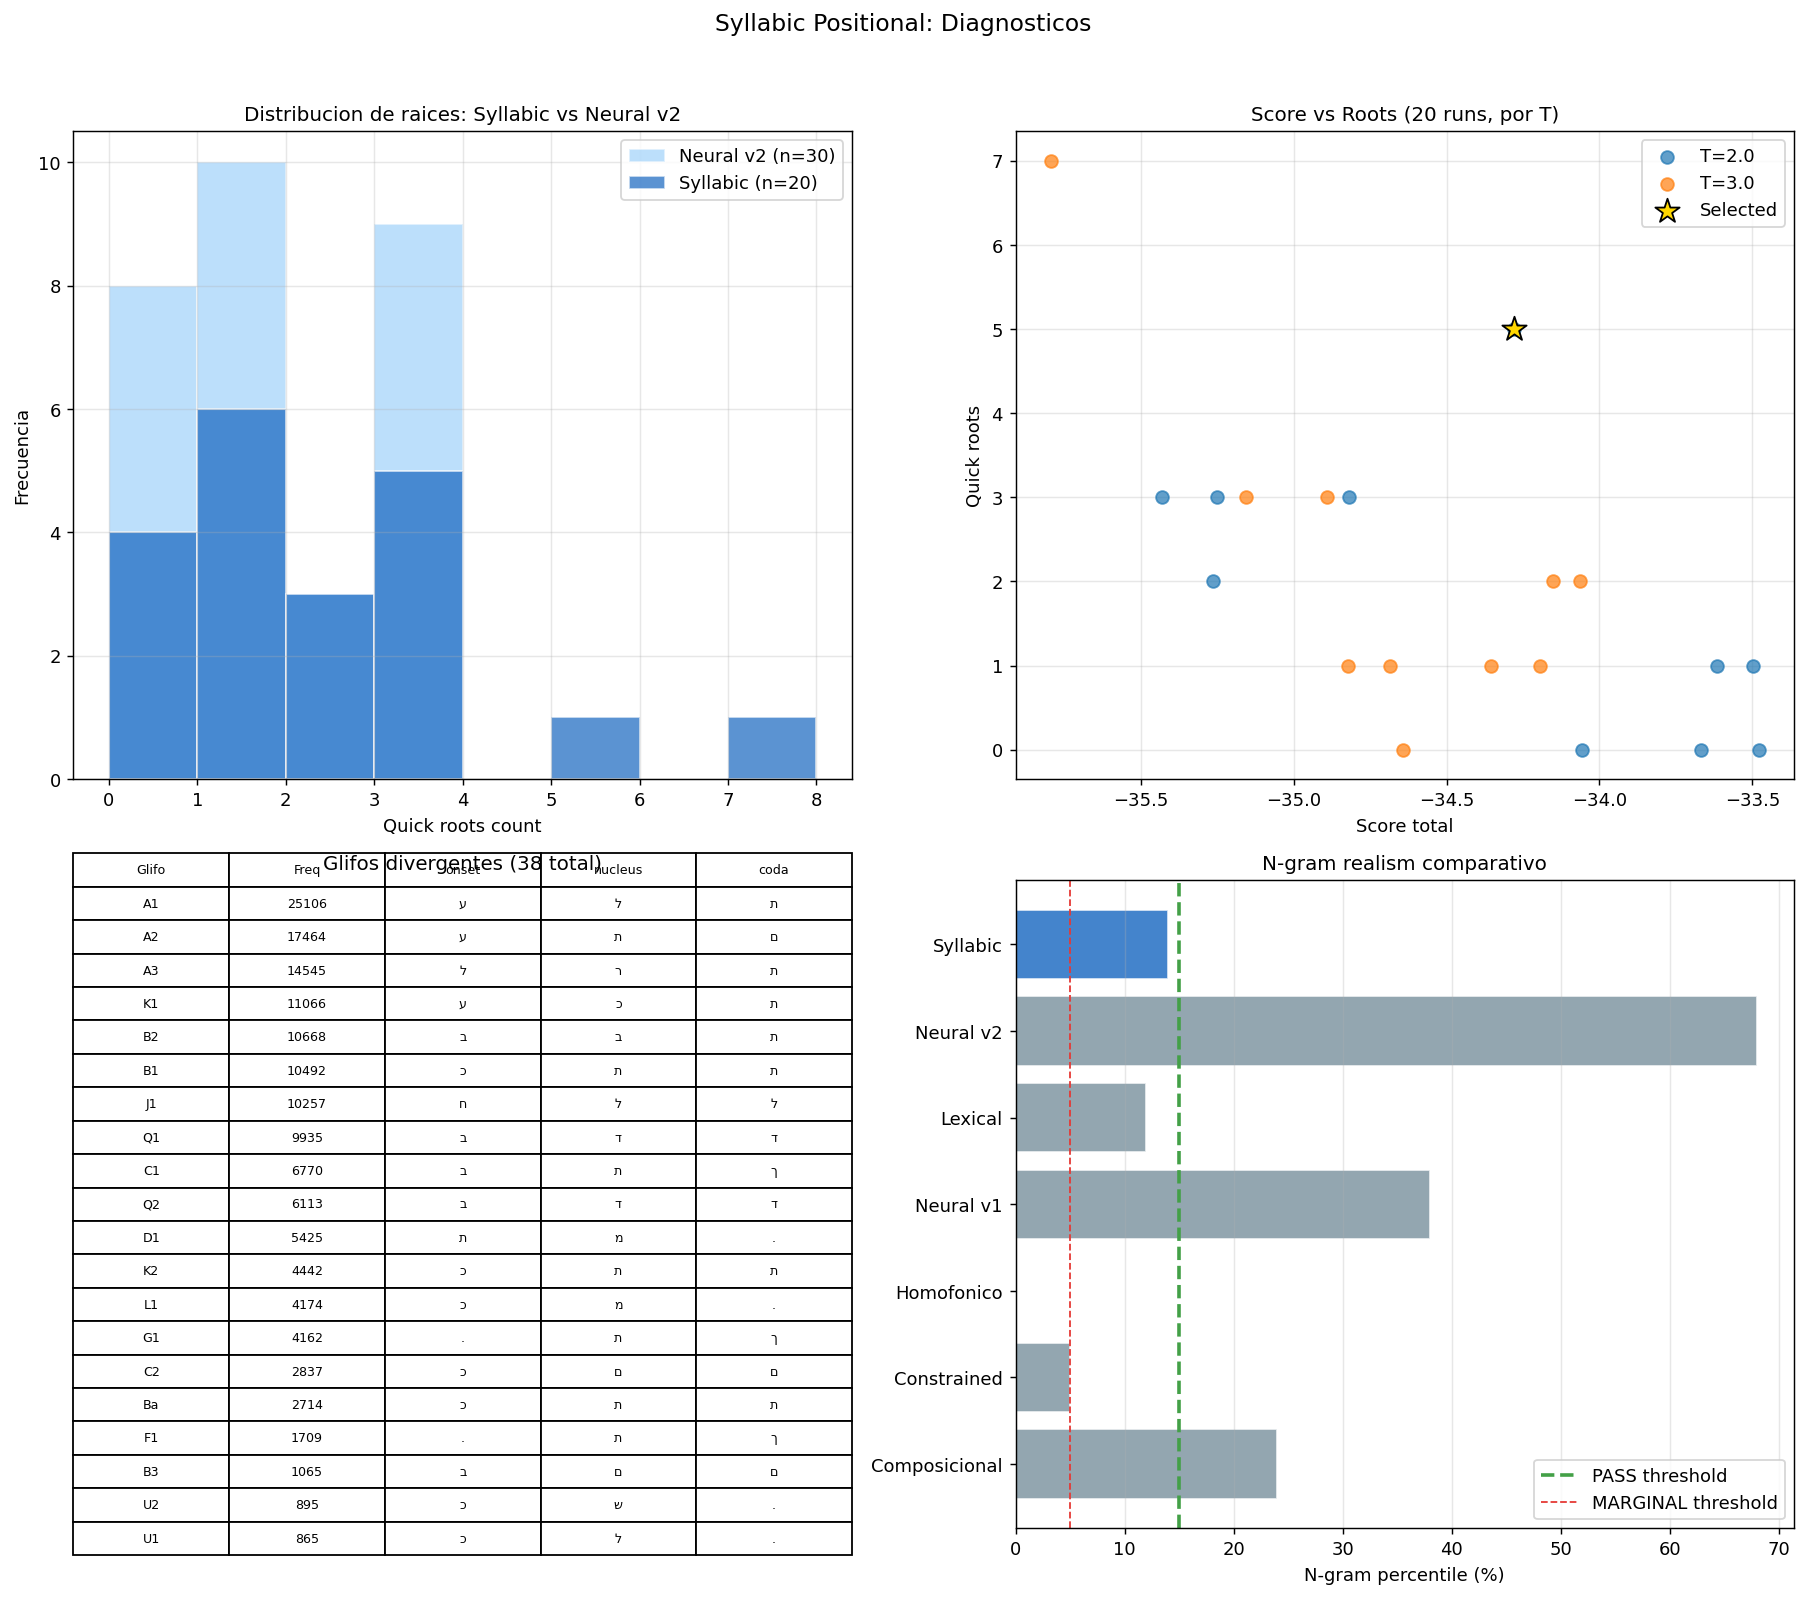

In [13]:
# -- Cell 13: Visualisations --

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Plot 1: Root histogram: syllabic vs neural v2
ax = axes[0, 0]
roots_syl = [r['n_roots'] for r in em_results]
# Load neural v2 roots if available
roots_v2 = []
if 'Neural v2' in prev_results:
    for r in prev_results['Neural v2'].get('multi_seed_results', []):
        roots_v2.append(r.get('n_roots', 0))
    for r in prev_results['Neural v2'].get('hard_k_results', []):
        roots_v2.append(r.get('n_roots', 0))
max_root = max(max(roots_syl, default=0), max(roots_v2, default=0)) + 2
if roots_v2:
    ax.hist(roots_v2, bins=range(0, max_root), alpha=0.6,
            color='#90CAF9', label=f'Neural v2 (n={len(roots_v2)})', edgecolor='white')
ax.hist(roots_syl, bins=range(0, max_root), alpha=0.7,
        color='#1565C0', label=f'Syllabic (n={len(roots_syl)})', edgecolor='white')
ax.set_xlabel('Quick roots count')
ax.set_ylabel('Frequency')
ax.set_title('Root distribution: Syllabic vs Neural v2')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Score vs roots scatter (20 runs, colored by T)
ax = axes[0, 1]
for T_val in T_VALUES:
    runs_t = [r for r in em_results if r['T'] == T_val]
    ax.scatter([r['score'] for r in runs_t], [r['n_roots'] for r in runs_t],
               s=50, alpha=0.7, label=f'T={T_val}', zorder=3)
# Mark best
ax.scatter([BEST['score']], [BEST['n_roots']], c='gold', s=200, marker='*',
           edgecolors='black', linewidths=1, zorder=5, label='Selected')
ax.set_xlabel('Score total')
ax.set_ylabel('Quick roots')
ax.set_title('Score vs Roots (20 runs, by T)')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Heatmap 3-panel (onset/nucleus/coda) for divergent glyphs
ax = axes[1, 0]
div_glyphs = [g for g in VOCAB
              if len(glyph_active_positions.get(g, set())) > 1
              and mapping_syl.n_divergent() > 0]
# Get actual divergent glyphs
div_glyphs = []
for g in VOCAB:
    active = glyph_active_positions.get(g, set())
    if len(active) < 2:
        continue
    chars_at_pos = set()
    for pos in active:
        table = mapping_syl._get_table(pos)
        if g in table:
            chars_at_pos.add(table[g])
    if len(chars_at_pos) > 1:
        div_glyphs.append(g)

if div_glyphs:
    # Show divergent glyphs with their mappings per position
    div_data = []
    for g in sorted(div_glyphs, key=lambda x: glyph_freq.get(x, 0), reverse=True)[:20]:
        row = {'Glyph': g, 'Freq': glyph_freq.get(g, 0)}
        for pos in POSITIONS:
            table = mapping_syl._get_table(pos)
            active = glyph_active_positions.get(g, set())
            row[pos] = table.get(g, '-') if pos in active else '.'
        div_data.append(row)
    div_df = pd.DataFrame(div_data)
    # Create text-based heatmap
    ax.axis('off')
    ax.set_title(f'Divergent glyphs ({len(div_glyphs)} total)')
    table_plot = ax.table(cellText=div_df.values, colLabels=div_df.columns,
                          loc='center', cellLoc='center')
    table_plot.auto_set_font_size(False)
    table_plot.set_fontsize(7)
    table_plot.scale(1, 1.3)
else:
    ax.text(0.5, 0.5, 'No divergent glyphs found\n(3 tables collapsed to identical)',
            ha='center', va='center', fontsize=12, transform=ax.transAxes)
    ax.set_title('Divergent glyphs')
    ax.axis('off')

# Plot 4: Comparative n-gram percentile bar chart (7 methods)
ax = axes[1, 1]
methods = ['Composicional', 'Constrained', 'Homofonico', 'Neural v1', 'Lexical', 'Neural v2', 'Syllabic']
ngram_vals = []
for m in methods:
    if m == 'Syllabic':
        ngram_vals.append(pct_ngram)
    elif m == 'Composicional':
        ngram_vals.append(24.0)
    elif m == 'Constrained':
        ngram_vals.append(5.0)
    elif m == 'Neural v1':
        ngram_vals.append(38.0)
    else:
        val = get_prev_metric(m, 'validation_details', 'ngram_percentile', default=None)
        if val is not None and val != '--':
            ngram_vals.append(float(val))
        else:
            ngram_vals.append(0)

colors = ['#78909C'] * (len(methods) - 1) + ['#1565C0']
ax.barh(methods, ngram_vals, color=colors, alpha=0.8, edgecolor='white')
ax.axvline(15, color='#43A047', linestyle='--', linewidth=2, label='PASS threshold')
ax.axvline(5, color='#E53935', linestyle='--', linewidth=1, label='MARGINAL threshold')
ax.set_xlabel('N-gram percentile (%)')
ax.set_title('Comparative n-gram realism')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3, axis='x')

plt.suptitle('Syllabic Positional: Diagnostics', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [14]:
# -- Cell 14: Export results -> syllabic_resultados.json --

# Serialize the 3 mappings
mapping_onset_ser = {g: c for g, c in mapping_syl.mapping_onset.items()}
mapping_nucleus_ser = {g: c for g, c in mapping_syl.mapping_nucleus.items()}
mapping_coda_ser = {g: c for g, c in mapping_syl.mapping_coda.items()}

# Posterior serializable
posterior_serializable = {}
for pos in POSITIONS:
    posterior_serializable[pos] = {}
    if pos in posterior_syl:
        for g, dist in posterior_syl[pos].items():
            posterior_serializable[pos][g] = {c: round(p, 4) for c, p in dist.items() if p > 0.01}

resultados = {
    'metadata': {
        'notebook': '15_syllabic_positional.ipynb',
        'model': 'syllabic_positional_3tables',
        'language': 'hebrew',
        'description': 'Syllabic positional: 3 mapping tables (onset/nucleus/coda) + LSTM',
    },
    'positional_stats': {
        'n_glyphs_1pos': int(n_1pos),
        'n_glyphs_2pos': int(n_2pos),
        'n_glyphs_3pos': int(n_3pos),
        'total_mapping_entries': int(total_entries),
        'pct_position_locked': round(float(100 * n_1pos / len(VOCAB)), 1),
        'n_divergent': int(mapping_syl.n_divergent()),
        'n_multi_position': int(mapping_syl.n_multi_position()),
        'pct_divergent': round(float(mapping_syl.n_divergent() / max(mapping_syl.n_multi_position(), 1)), 3),
    },
    'neural_lm': {
        'architecture': 'LSTM 2-layer, embed=32, hidden=192, dropout=0.2',
        'n_params': sum(p.numel() for p in neural_lm.parameters()),
        'train_epochs': len(train_losses),
        'best_val_loss': float(best_val_loss),
    },
    'em_results': [{
        'T': float(r['T']), 'seed': int(r['seed']),
        'score': round(float(r['score']), 4),
        'K_eff': int(r['K_eff']), 'grammar': round(float(r['grammar']), 3),
        'n_roots': int(r['n_roots']),
        'roots_list': sorted(r['roots']),
        'n_divergent': int(r['n_divergent']),
        'iter_converged': int(r['iter_converged']),
        'elapsed': round(float(r['elapsed']), 1),
    } for r in em_results],
    'best_candidate': {
        'T': float(BEST['T']),
        'seed': int(BEST['seed']),
        'score': round(float(BEST['score']), 4),
        'K_eff': int(BEST['K_eff']),
        'grammar': round(float(BEST['grammar']), 3),
        'n_roots_quick': int(BEST['n_roots']),
        'n_divergent': int(BEST['n_divergent']),
    },
    'mcmc_results': {
        'n_chains': N_CHAINS,
        'n_iter': N_ITER,
        'burn_in': BURN_IN,
        'best_score': round(float(global_best_score), 4),
        'K_eff': len(set(global_best.mapping.values())),
        'n_divergent': int(global_best.n_divergent()),
        'pct_converged_rhat': round(float(pct_converged), 1),
        'chain_accept_rates': [round(float(ch['accept_rate']), 3) for ch in mcmc_chains],
    },
    'validation_scorecard': {s['Test']: s['Verdict'] for s in scorecard},
    'validation_details': {
        'collapse_mean_z': round(float(mean_z), 3),
        'ngram_percentile': round(float(pct_ngram), 1),
        'ngram_jsd': round(float(real_jsd), 4),
        'roots_matched': int(len(roots_matched)),
        'enrichment': round(float(enrichment), 1),
        'cardinality_ratio': round(float(K_ratio), 3),
        'grammar_anchor_pct': round(float(pct_anchor), 3),
        'positional_divergence_pct': round(float(100 * pct_div), 1),
    },
    'scorecard_summary': f'{n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL',
    'mapping_onset': mapping_onset_ser,
    'mapping_nucleus': mapping_nucleus_ser,
    'mapping_coda': mapping_coda_ser,
    'posterior_top': posterior_serializable,
    'rhat': {g: round(float(v), 4) for g, v in rhat_syl.items()
             if isinstance(v, (int, float, np.floating)) and not np.isnan(v)},
    'comparison_table': comparison_rows,
    'em_summary': {
        'n_seeds_per_T': N_SEEDS,
        'T_values': T_VALUES,
        'total_runs': len(em_results),
    },
}

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.integer,)): return int(obj)
        if isinstance(obj, (np.floating,)): return float(obj)
        if isinstance(obj, np.ndarray): return obj.tolist()
        if isinstance(obj, set): return sorted(obj)
        return super().default(obj)

with open('syllabic_resultados.json', 'w') as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False, cls=NumpyEncoder)
print('Results exported to syllabic_results.json')
print(f'Keys: {list(results.keys())}')

print(f'\n-- Final summary --')
print(f'Model: Syllabic Positional (3 tables)')
print(f'Best candidate: T={BEST["T"]}, seed={BEST["seed"]}')
print(f'Quick roots (pre-MCMC): {BEST["n_roots"]}')
print(f'Validated roots (post-MCMC): {len(roots_matched)}')
print(f'Divergent glyphs: {mapping_syl.n_divergent()}/{mapping_syl.n_multi_position()}')
print(f'Scorecard: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')
print(f'R-hat convergence: {pct_converged:.0f}%')

# Per-T summary
for T_val in T_VALUES:
    runs_t = [r for r in em_results if r['T'] == T_val]
    print(f'\nT={T_val} ({len(runs_t)} runs):')
    print(f'  Roots: {np.mean([r["n_roots"] for r in runs_t]):.1f} +- '
          f'{np.std([r["n_roots"] for r in runs_t]):.1f}')
    print(f'  Divergent: {np.mean([r["n_divergent"] for r in runs_t]):.1f} +- '
          f'{np.std([r["n_divergent"] for r in runs_t]):.1f}')

Resultados exportados a syllabic_resultados.json
Keys: ['metadata', 'positional_stats', 'neural_lm', 'em_results', 'best_candidate', 'mcmc_results', 'validation_scorecard', 'validation_details', 'scorecard_summary', 'mapping_onset', 'mapping_nucleus', 'mapping_coda', 'posterior_top', 'rhat', 'comparison_table', 'em_summary']

-- Resumen final --
Modelo: Syllabic Positional (3 tablas)
Mejor candidato: T=2.0, seed=1
Quick roots (pre-MCMC): 5
Validated roots (post-MCMC): 5
Divergent glyphs: 38/44
Scorecard: 4 PASS / 2 MARGINAL / 0 FAIL
R-hat convergencia: 92%

T=2.0 (10 runs):
  Roots: 1.8 +- 1.6
  Divergent: 38.0 +- 2.5

T=3.0 (10 runs):
  Roots: 2.1 +- 1.9
  Divergent: 38.5 +- 1.8
